# 05 · Finding periods: GLS, PDC, USuRPER and partial periodograms

**What you'll learn**

- GLS and PDC periodograms of a scalar series (e.g. RVs), on a frequency grid in 1/day
- what a PDC p-value means, and why it is a *single-frequency* (local) p-value
- the error-aware PDC, for points with very different error bars
- USuRPER: a periodogram of the spectra themselves, with no RVs needed
- the partial periodograms, which separate Doppler shifts from line-shape changes

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import Observations, TimeSeries
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates

plt.rcParams.update({
    "figure.figsize": (8, 3.2), "figure.dpi": 100, "figure.constrained_layout.use": True,
    "font.size": 11, "axes.titlesize": 11, "legend.fontsize": 9, "legend.frameon": False,
})

def peak(detector, key):
    """(period in days, power) of the highest peak of a stored periodogram."""
    f, p = detector.results_frequency[key], detector.results_power[key]
    return 1 / f[np.argmax(p)], p.max()

def power_at(detector, key, period):
    """Power of a stored periodogram at the grid frequency closest to 1/period (days)."""
    f, p = detector.results_frequency[key], detector.results_power[key]
    return p[np.argmin(np.abs(f - 1 / period))]

## 1. A scalar series: GLS and PDC

40 measurements at random times over 100 days of a sinusoid with a 7.3-day period, plus noise.
Values that are not spectra go straight into a `TimeSeries`, and `Observations` wraps it.

In [2]:
rng = np.random.default_rng(42)
t = np.sort(rng.uniform(0, 100, 40))                   # days
P_true = 7.3
y = np.sin(2 * np.pi * t / P_true) + 0.5 * rng.standard_normal(t.size)

obs = Observations(time_series=TimeSeries(times=t, vals=list(y)))

**The frequency grid.** Frequencies are in 1/day. A peak is about $1/T$ wide ($T$ = 100 days,
the time span), so the grid step must be several times finer than 0.01/day:
`periodogram_grid_resolution=2000` means 2000 points per 1/day, a step of 0.0005/day.

In [3]:
obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
pd = obs.periodicity_detector
print(f"{pd.frequency_grid.size} frequencies from {pd.frequency_grid[0]} to {pd.frequency_grid[-1]:.4f} 1/day")

pd.calc_gls()               # generalised Lomb-Scargle: fits a sinusoid at every frequency
pd.calc_pdc()               # phase distance correlation: no assumed shape
for key in ("GLS", "PDC_unbiased"):
    period, power = peak(pd, key)
    print(f"{key:13s}: highest peak at P = {period:.3f} days (power {power:.3f})")

1980 frequencies from 0.01 to 0.9995 1/day
GLS          : highest peak at P = 7.273 days (power 0.833)
PDC_unbiased : highest peak at P = 7.326 days (power 0.643)


GLS fits a sinusoid at each trial frequency. PDC (Zucker 2018) asks a more general question:
are pairs of points that are close in *phase* also close in *value*? It is a distance
correlation, so it works for any periodic shape.

**p-values.** `calc_pdc_pval` turns an (unbiased) PDC power into a p-value (Shen et al. 2019):
the probability of a peak this high *at one given frequency* if there were no signal. It is
local: searching many frequencies gives noise many chances. A rough look-elsewhere factor is
the number of independent frequencies, about $T \times (f_{\max} - f_{\min})$.

In [4]:
p_local = pd.calc_pdc_pval([peak(pd, "PDC_unbiased")[1]])[0]
n_indep = np.ptp(t) * (pd.freq_range[1] - pd.freq_range[0])
level = pd.calc_pdc_pval([1e-3], inverse_sf=True)[0]

print(f"local p-value of the PDC peak: {p_local:.1e}")
print(f"~{n_indep:.0f} independent frequencies -> global p-value roughly {min(1, p_local * n_indep):.1e}")
print(f"PDC power for a local p-value of 1e-3: {level:.3f}")

local p-value of the PDC peak: 2.4e-07
~92 independent frequencies -> global p-value roughly 2.2e-05
PDC power for a local p-value of 1e-3: 0.246


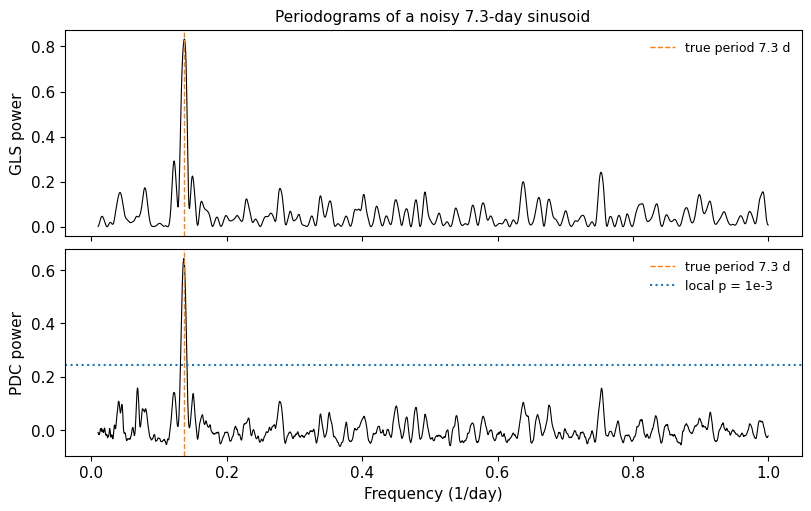

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, key in zip(axs, ("GLS", "PDC_unbiased")):
    ax.plot(pd.results_frequency[key], pd.results_power[key], "k", lw=0.8)
    ax.axvline(1 / P_true, color="tab:orange", ls="--", lw=1, label=f"true period {P_true} d")
    ax.set_ylabel(f"{key.split('_')[0]} power")
axs[1].axhline(level, color="tab:blue", ls=":", label="local p = 1e-3")
axs[0].set_title("Periodograms of a noisy 7.3-day sinusoid")
axs[1].set_xlabel("Frequency (1/day)")
axs[0].legend()
axs[1].legend()
plt.show()

(`pd.plot_periodograms()` draws every stored periodogram in one call.)

## 2. When error bars differ: the error-aware PDC

If some points are much noisier than others, the plain PDC still treats them all alike.
`calc_pdc(errors=True)` uses each pair's error bars in the distance (Binnenfeld, Shahaf &
Zucker 2024) and stores `'PDC_errors_unbiased'`. One data set can go either way, so we compare
the two over 30 simulated data sets with exponentially distributed error bars, and count how
often the highest peak is the true period:

In [6]:
hits = {"PDC_unbiased": 0, "PDC_errors_unbiased": 0}
for seed in range(30):
    r = np.random.default_rng(seed)
    ts = np.sort(r.uniform(0, 100, 40))
    err = r.exponential(1.0, ts.size)                  # very unequal error bars
    ys = np.sin(2 * np.pi * ts / P_true) + err * r.standard_normal(ts.size)
    o = Observations(time_series=TimeSeries(times=ts, vals=list(ys), errors=list(err)))
    o.init_periodicity_detector(freq_range=(0.02, 1.0), periodogram_grid_resolution=1000)
    o.periodicity_detector.calc_pdc()
    o.periodicity_detector.calc_pdc(errors=True)
    for key in hits:
        hits[key] += abs(1 / peak(o.periodicity_detector, key)[0] - 1 / P_true) < 0.01

for key, n in hits.items():
    print(f"{key:20s}: true period found in {n} of 30 data sets")

PDC_unbiased        : true period found in 23 of 30 data sets
PDC_errors_unbiased : true period found in 26 of 30 data sets


## 3. Periodograms of spectra: USuRPER

USuRPER (Binnenfeld, Shahaf & Zucker 2020) skips the RVs: it applies the PDC idea to the spectra
themselves, with the distance between two spectra as the "difference in value". Any periodic
change of the spectrum counts, whether a Doppler shift or a change in the line shapes.

A toy star, simulated "like HARPS": its spectrum moves with a 7.3-day period ($K$ = 30 km/s),
and a faint second spectrum (15% line depth) moves *relative to it* with a 3.1-day period, so the
combined line shapes change every 3.1 days. (Think of it as a stand-in for any line-profile
variation.)

In [7]:
P1, P2 = 7.3, 3.1                                       # days
v1 = 30.0 * np.sin(2 * np.pi * t / P1)                  # km/s
v2 = v1 + 20.0 + 15.0 * np.sin(2 * np.pi * t / P2)

sim = Simulation(like="HARPS", windows_A=[(5000, 5100)], times=t, rv_kms=np.column_stack([v1, v2]),
                 components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0, amplitude=1.0),
                             dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.15)],
                 snr=100, noise="constant", seed=7)
spec_obs = Observations(survey="SIMULATED", simulation=sim)
spec_obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
spd = spec_obs.periodicity_detector

spd.calc_usurper()
period, power = peak(spd, "USURPER_unbiased")
print(f"USuRPER: highest peak at P = {period:.3f} days")
print(f"USuRPER power at P1 = {P1} d: {power_at(spd, 'USURPER_unbiased', P1):.3f}, "
      f"at P2 = {P2} d: {power_at(spd, 'USURPER_unbiased', P2):.3f}")

USuRPER: highest peak at P = 7.299 days
USuRPER power at P1 = 7.3 d: 0.614, at P2 = 3.1 d: -0.042


USuRPER sees the dominant change, the 7.3-day Doppler shift; next to it, the much smaller
3.1-day shape change does not stand out.

## 4. Separating shifts from shapes: partial periodograms

The partial periodograms (Binnenfeld et al. 2022) use the RVs to split the two:

- **shift**: the periodicity of the RVs, with whatever the line-shape changes explain removed;
- **shape**: the periodicity of the spectra shifted to rest by the RVs (so only shape changes
  remain), with whatever the RVs explain removed.

First the RVs, against the primary's template (notebook 02); `calc_rv_against_template` stores
them where the periodograms read them.

In [8]:
template = component_templates(sim)[0]
spec_obs.calc_rv_against_template(template, dv=0.1, vel_bound=60)
print(f"RV rms about the primary's true velocity: {np.std(spec_obs.vels - v1) * 1e3:.0f} m/s "
      "(the faint spectrum pulls the CCF)")

spd.calc_gls()
spd.calc_partial_periodogram("shift")
spd.calc_partial_periodogram("shape")
for key in ("GLS", "USURPER_unbiased", "partial_shift", "partial_shape"):
    period, power = peak(spd, key)
    print(f"{key:16s}: highest peak at P = {period:.3f} days")
print(f"partial_shape power at P2 = {P2} d: {power_at(spd, 'partial_shape', P2):.3f}, "
      f"at P2/2 = {P2 / 2} d: {power_at(spd, 'partial_shape', P2 / 2):.3f}")

  0%|          | 0/40 [00:00<?, ?it/s]

 35%|███▌      | 14/40 [00:00<00:00, 132.05it/s]

 72%|███████▎  | 29/40 [00:00<00:00, 140.65it/s]

100%|██████████| 40/40 [00:00<00:00, 140.59it/s]

RV rms about the primary's true velocity: 73 m/s (the faint spectrum pulls the CCF)
GLS             : highest peak at P = 7.299 days
USURPER_unbiased: highest peak at P = 7.299 days
partial_shift   : highest peak at P = 7.326 days
partial_shape   : highest peak at P = 3.101 days
partial_shape power at P2 = 3.1 d: 0.419, at P2/2 = 1.55 d: 0.380


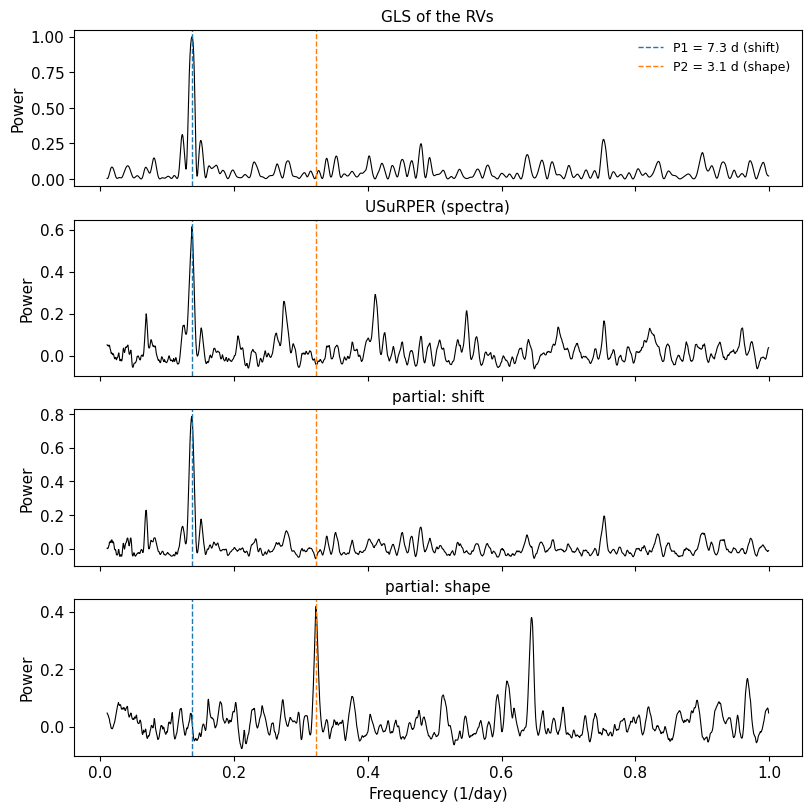

In [9]:
keys = {"GLS": "GLS of the RVs", "USURPER_unbiased": "USuRPER (spectra)",
        "partial_shift": "partial: shift", "partial_shape": "partial: shape"}
fig, axs = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (key, label) in zip(axs, keys.items()):
    ax.plot(spd.results_frequency[key], spd.results_power[key], "k", lw=0.8)
    ax.axvline(1 / P1, color="tab:blue", ls="--", lw=1, label=f"P1 = {P1} d (shift)")
    ax.axvline(1 / P2, color="tab:orange", ls="--", lw=1, label=f"P2 = {P2} d (shape)")
    ax.set_ylabel("Power")
    ax.set_title(label)
axs[0].legend(loc="upper right")
axs[-1].set_xlabel("Frequency (1/day)")
plt.show()

Each periodogram answers a different question: the RVs and the shift periodogram see the orbit
(7.3 d), and only the shape periodogram picks out the 3.1-day line-shape change. Its second peak,
at half that period, is real too: the injected offset $20 + 15\sin\varphi$ km/s takes each value
twice per cycle, so the line shape does too.

## Summary / next

- Build the detector with `init_periodicity_detector(freq_range, periodogram_grid_resolution)`
  (1/day; grid step finer than 1/T), then `calc_gls`, `calc_pdc`, `calc_usurper`,
  `calc_partial_periodogram`; results are in `results_frequency` / `results_power`.
- PDC p-values (`calc_pdc_pval`) are local, for one frequency; correct for the number of
  frequencies searched.
- `calc_pdc(errors=True)` uses the error bars; with very unequal ones it found the true period
  more often.
- USuRPER works on the spectra directly; the partial periodograms tell Doppler shifts from
  line-shape changes.

**Next:** `06_end_to_end.ipynb`: from simulated spectra to a measured orbit.